In [1]:
import matplotlib.pyplot as plt

## Style setup — PDEStyle colors + larger fonts
import PDEStyle as PS
ms = PS.MyStyleSet()
ms.SetMPLcolors()   # sets matplotlib prop_cycle to PDEStyle colors

plt.rcParams.update({
    'font.size': 14,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13,
    'legend.fontsize': 11,
})

In [9]:
import numpy as np
import pandas as pd
from scipy.interpolate import interp1d
from scipy import integrate as spInt

# ── Operating voltage for internal PDE ─
VOLTAGE = 4.5   # V_ov; available: 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 5.5
FF1 = 0.6 # fill factor for total PDE

# ── Optics + internal PDE ──────────────────────────────────────────────────
# optics_df = pd.read_csv('data/optics_HPK-VUV4_noWindow_17nmOxide_defaultData_globalPar_160k.csv')
# pde_df    = pd.read_csv('data/internalPDE_HPK-VUV4_noWindow_17nmOxide_defaultData_globalPar_160k.csv')

optics_df = pd.read_csv('data/optics_HPK-VUV4_noWindow_17nmOxide_defaultData_globalPar_145K_june12.csv')
# optics_df = pd.read_csv('data/data/optics_HPK-VUV4_withWindow_17nmOxide_defaultData_globalPar_145K_june12.csv')

pde_df    = pd.read_csv('data/internalPDE_HPK-VUV4_17nmOxide_defaultData_globalPar_145K_june12.csv')
def get_total_pde(angle, medium, voltage=VOLTAGE, FF = FF1):
    """Total PDE = optics transmission × internal PDE at given angle / medium / voltage."""
    op   = optics_df[optics_df['angle'] == angle][['wavelength', f'transmission_{medium}']].copy()
    pd_v = pde_df[pde_df['voltage'] == voltage][['wavelength', 'internalPDE']].copy()
    merged = pd.merge(op, pd_v, on='wavelength').sort_values('wavelength')
    wl    = merged['wavelength'].values
    total = merged[f'transmission_{medium}'].values * merged['internalPDE'].values
    return wl, FF*total

wl_0_vac,  pde_0_vac  = get_total_pde(0.0,  'vacuum')
wl_0_cf4,  pde_0_cf4  = get_total_pde(0.0,  'cf4')
wl_45_vac, pde_45_vac = get_total_pde(45.0, 'vacuum')
wl_45_cf4, pde_45_cf4 = get_total_pde(45.0, 'cf4')

print(f"Wavelength range: {wl_0_vac[0]:.0f}–{wl_0_vac[-1]:.0f} nm  ({len(wl_0_vac)} points)")
print(f"Peak total PDE (0°, vacuum): {pde_0_vac.max():.3f}  @ {wl_0_vac[pde_0_vac.argmax()]:.0f} nm")
print(f"Peak total PDE (0°, CF4):   {pde_0_cf4.max():.3f}  @ {wl_0_cf4[pde_0_cf4.argmax()]:.0f} nm")

# ── LP 500 nm long-pass filter ─────────────────────────────────────────────
filt_df = pd.read_csv('data/LP_500nm.csv')
filt_x  = filt_df.iloc[:,0].values
filt_y  = filt_df.iloc[:,1].values / 100.0   # "% Transmission" → fraction

# ── Scintillation spectra (CF4, 5 bar, Morozov) ────────────────────────────
uv_scint  = np.loadtxt('data/cf4Scint_5bar_UV.txt',  comments='#')
vis_scint = np.loadtxt('data/cf4Scint_5bar_Vis.txt', comments='#')
uv_x,  uv_y  = uv_scint[:,0],  np.maximum(uv_scint[:,1],  0)
vis_x, vis_y = vis_scint[:,0], np.maximum(vis_scint[:,1], 0)

# ── Gernhauser VUV spectrum (CF4, 0.5 bar) ─────────────────────────────────
gx, gy = np.loadtxt('oldStitching/literature_data/gernhauser_cf4_05bar.csv',
                    skiprows=2, delimiter=',', unpack=True)
srt    = np.argsort(gx)
gern_x = gx[srt];  gern_y = np.maximum(gy[srt], 0)

# ── Morozov 1-bar spectrum (for stitching scale factor) ────────────────────
mor_raw = np.genfromtxt('oldStitching/literature_data/morozov_2010_spectrum.csv',
                        skip_header=2, delimiter=',')
m1x_raw, m1y_raw = mor_raw[:,0], mor_raw[:,1]
valid  = ~np.isnan(m1x_raw) & ~np.isnan(m1y_raw)
mor1_x = m1x_raw[valid];  mor1_y = np.maximum(m1y_raw[valid], 0)

print(f"\nGernhauser:  {gern_x[0]:.1f}–{gern_x[-1]:.1f} nm")
print(f"Morozov 1b:  {mor1_x[0]:.1f}–{mor1_x[-1]:.1f} nm")
print(f"UV 5 bar:    {uv_x[0]:.1f}–{uv_x[-1]:.1f} nm")
print(f"Vis 5 bar:   {vis_x[0]:.1f}–{vis_x[-1]:.1f} nm")


Wavelength range: 140–1198 nm  (424 points)
Peak total PDE (0°, vacuum): 0.324  @ 498 nm
Peak total PDE (0°, CF4):   0.370  @ 498 nm

Gernhauser:  135.7–316.7 nm
Morozov 1b:  212.1–795.8 nm
UV 5 bar:    204.0–503.4 nm
Vis 5 bar:   503.4–797.8 nm


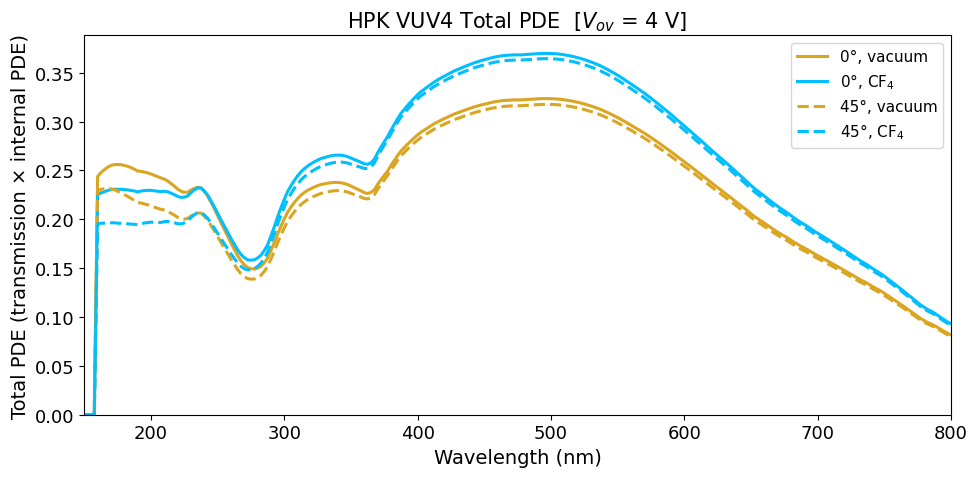

In [10]:
# ── Total PDE: 0° and 45°, vacuum and CF4 ─────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(wl_0_vac,  pde_0_vac,  color=ms.air.col, ls=ms.line1, lw=2.2,
        label=r'0°, vacuum')
ax.plot(wl_0_cf4,  pde_0_cf4,  color=ms.cf4.col, ls=ms.line1, lw=2.2,
        label=r'0°, CF$_4$')
ax.plot(wl_45_vac, pde_45_vac, color=ms.air.col, ls=ms.line2, lw=2.2,
        label=r'45°, vacuum')
ax.plot(wl_45_cf4, pde_45_cf4, color=ms.cf4.col, ls=ms.line2, lw=2.2,
        label=r'45°, CF$_4$')

ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Total PDE (transmission × internal PDE)')
ax.set_title(fr'HPK VUV4 Total PDE  [$V_{{ov}}$ = {VOLTAGE:.0f} V]')
ax.set_xlim(150, 800)
ax.set_ylim(0, None)
ax.legend()
plt.tight_layout()
plt.show()


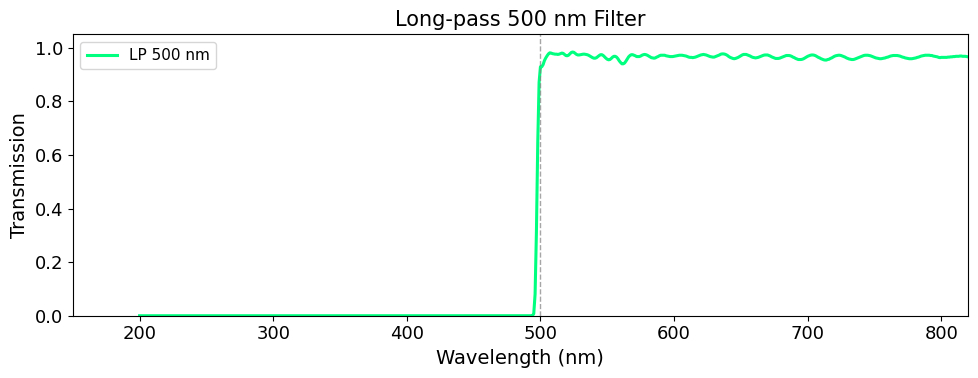

In [11]:
# ── LP 500 nm long-pass filter ─────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 4))

filt_mask = (filt_x >= 150) & (filt_x <= 820)
ax.plot(filt_x[filt_mask], filt_y[filt_mask], color=ms.green.col, lw=2.2,
        label='LP 500 nm')
ax.axvline(500, color='grey', ls='--', lw=1, alpha=0.7)

ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Transmission')
ax.set_title('Long-pass 500 nm Filter')
ax.set_xlim(150, 820)
ax.set_ylim(0, 1.05)
ax.legend()
plt.tight_layout()
plt.show()


In [12]:
# ── VUV stitching: scale Gernhauser (0.5 bar) to 5-bar spectrum ───────────
#
# Method (mirrors data_stitching2.ipynb):
#   1. Overlap region = max(Morozov-1bar start, Gernhauser start) → Gernhauser end
#   2. ratio1 = integral(Morozov 1-bar, overlap) / integral(Gernhauser, overlap)
#         → scales Gernhauser to match Morozov 1-bar in overlap
#   3. ratio2 = ratio1 × 1.1  (Morozov: 0.5-bar UV yield is 10% above 1-bar)
#         → scales Gernhauser to 0.5-bar level (same pressure as Gernhauser)
#   4. mUVScale = ∫UV(1-bar) / ∫UV(5-bar)
#         → UV yield ratio between 1-bar and 5-bar
#   5. scale_VUV = ratio2 / mUVScale
#         → scales Gernhauser VUV to 5-bar, assuming VUV/UV ratio holds
#

# Overlap: Morozov 1-bar ∩ Gernhauser
firstW_ov = mor1_x[0]         # ~212 nm
lastW_ov  = gern_x[-1]        # ~317 nm

# Dense grid in overlap
wov = np.linspace(firstW_ov, lastW_ov, 2000)

ipGern = interp1d(gern_x, gern_y, kind='linear', bounds_error=False, fill_value=0.0)
ipMor1 = interp1d(mor1_x, mor1_y, kind='linear', bounds_error=False, fill_value=0.0)
ipUV5  = interp1d(uv_x,   uv_y,  kind='linear', bounds_error=False, fill_value=0.0)

a_mor1 = spInt.trapezoid(ipMor1(wov), wov)
a_gern = spInt.trapezoid(ipGern(wov), wov)
ratio1 = a_mor1 / a_gern

ratio2 = ratio1 * 1.1      # gernhauser is 0.5-bar; adjust morozov to match

# UV yield ratio: 1-bar vs 5-bar (integrate over the UV spectrum range)
wuv = np.linspace(uv_x[0], uv_x[-1], 5000)
Yuv_1bar = spInt.trapezoid(ipMor1(wuv), wuv)
Yuv_5bar = spInt.trapezoid(ipUV5(wuv),  wuv)
mUVScale = Yuv_1bar / Yuv_5bar

scale_VUV_5bar = ratio2 / mUVScale

print(f"Overlap region: {firstW_ov:.0f}–{lastW_ov:.0f} nm")
print(f"  Morozov 1-bar area in overlap: {a_mor1:.4f}")
print(f"  Gernhauser area in overlap:    {a_gern:.4f}")
print(f"  ratio1 (Mor1/Gern):            {ratio1:.4f}")
print(f"  ratio2 (×1.1 for 0.5 bar):    {ratio2:.4f}")
print(f"\nUV yield (1-bar):  {Yuv_1bar:.4f}")
print(f"UV yield (5-bar):  {Yuv_5bar:.4f}")
print(f"mUVScale (1/5):    {mUVScale:.4f}")
print(f"\nFinal VUV scale factor (Gernhauser → 5 bar): {scale_VUV_5bar:.4f}")

# ── Assemble full 5-bar spectrum ───────────────────────────────────────────
# VUV part: Gernhauser below the start of the 5-bar UV data
cut_idx  = np.searchsorted(gern_x, uv_x[0], side='left')
vuv_x    = gern_x[:cut_idx]
vuv_y    = gern_y[:cut_idx] * scale_VUV_5bar

full_x = np.concatenate([vuv_x, uv_x, vis_x])
full_y = np.concatenate([vuv_y, uv_y, vis_y])
srt2   = np.argsort(full_x)
full_x = full_x[srt2];  full_y = full_y[srt2]

ipFull = interp1d(full_x, full_y, kind='linear', bounds_error=False, fill_value=0.0)
print(f"\nFull spectrum assembled: {full_x[0]:.1f}–{full_x[-1]:.1f} nm ({len(full_x)} pts)")


Overlap region: 212–317 nm
  Morozov 1-bar area in overlap: 38.6770
  Gernhauser area in overlap:    538.8512
  ratio1 (Mor1/Gern):            0.0718
  ratio2 (×1.1 for 0.5 bar):    0.0790

UV yield (1-bar):  56.5222
UV yield (5-bar):  24.0544
mUVScale (1/5):    2.3498

Final VUV scale factor (Gernhauser → 5 bar): 0.0336

Full spectrum assembled: 135.7–797.8 nm (152 pts)


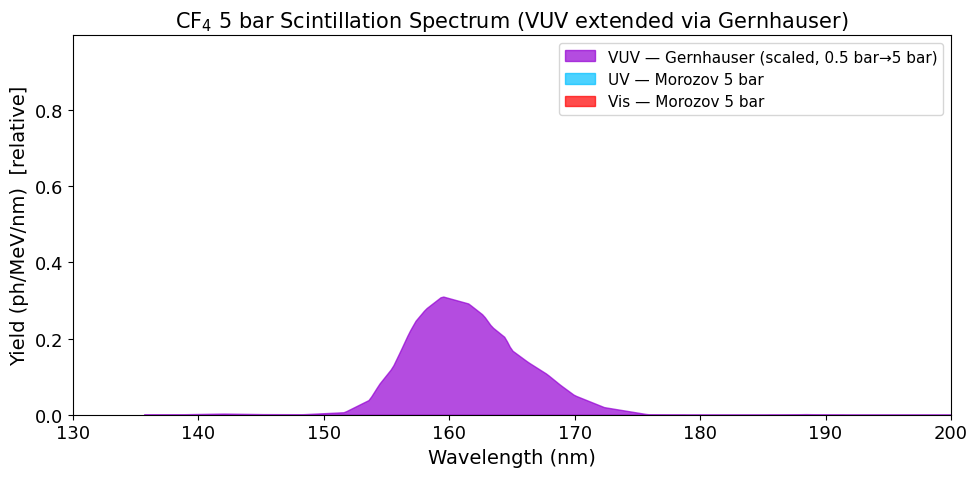

In [13]:
# ── CF4 5-bar scintillation spectrum (stitched) ────────────────────────────
wplot = np.linspace(full_x[0], full_x[-1], 3000)

fig, ax = plt.subplots(figsize=(10, 5))

wvuv  = wplot[wplot <= uv_x[0]]
wuv2  = wplot[(wplot > uv_x[0]) & (wplot <= vis_x[0])]
wvis2 = wplot[wplot > vis_x[0]]

ax.fill_between(wvuv,  ipFull(wvuv),  alpha=0.70, color=ms.lxe.col,
                label=r'VUV — Gernhauser (scaled, 0.5 bar→5 bar)')
ax.fill_between(wuv2,  ipFull(wuv2),  alpha=0.70, color=ms.cf4.col,
                label=r'UV — Morozov 5 bar')
ax.fill_between(wvis2, ipFull(wvis2), alpha=0.70, color=ms.red.col,
                label=r'Vis — Morozov 5 bar')

# Mark stitch boundaries
for xv in [uv_x[0], vis_x[0]]:
    ax.axvline(xv, color='grey', ls=':', lw=1.0, alpha=0.8)

ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Yield (ph/MeV/nm)  [relative]')
ax.set_title(r'CF$_4$ 5 bar Scintillation Spectrum (VUV extended via Gernhauser)')
ax.set_xlim(130, 200)
ax.set_ylim(0, None)
ax.legend()
plt.tight_layout()
plt.show()


VUV (Gernhauser) integral: 1.5165
UV (Morozov) integral:     14.5528
Total integral:            16.0692

Relative contributions:
  VUV: 9.4%
  UV:  90.6%


/var/folders/1y/pq_0h029381_cwg2wmchsdt00000gn/T/ipykernel_27142/3904607689.py:148: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


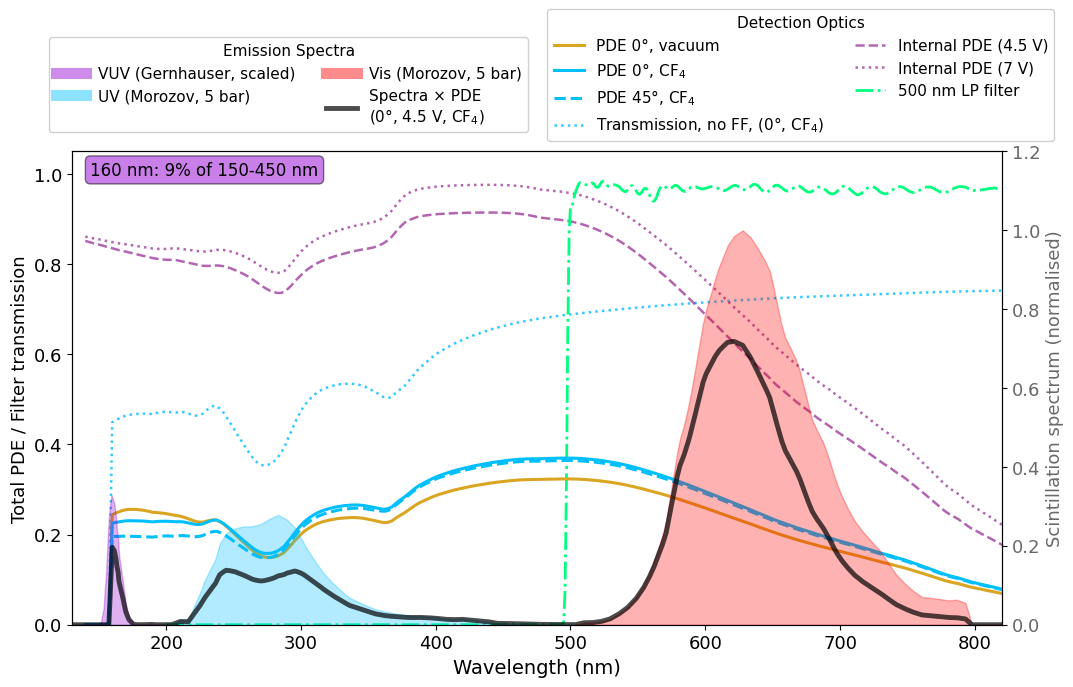

Saved: combined_optics_plot.pdf / .png


In [19]:
# ── Combined plot: PDE, filter, and CF4 scintillation spectrum ────────────
XLIM = (130, 820)
wfull = np.linspace(XLIM[0], XLIM[1], 4000)

# Flag to show separated components (transmission + internal PDE for CF4 0°)
SHOW_SEPARATED_PDE = True

# Create figure with GridSpec: legend areas at top, plot area below
fig = plt.figure(figsize=(12, 7))
gs = fig.add_gridspec(2, 1, height_ratios=[0.10, 0.90], hspace=0.05)
ax_leg_area = fig.add_subplot(gs[0])
ax_plot = fig.add_subplot(gs[1])
ax1 = ax_plot
ax2 = ax1.twinx()

# Hide the legend area axis but keep it for positioning legends
ax_leg_area.axis('off')

# ── Right axis: normalised scintillation spectrum (pushed to bottom) ───────
spec_max = full_y.max()
RIGHT_SCALE = 1.2   # y_right limit; spectrum sits in the bottom ~28% of the plot

wvuv_p  = wfull[wfull <= uv_x[0]]
wuv_p   = wfull[(wfull > uv_x[0]) & (wfull <= vis_x[0])]
wvis_p  = wfull[wfull > vis_x[0]]

ax2.fill_between(wvuv_p,  ipFull(wvuv_p)  / spec_max, color=ms.lxe.col,  alpha=0.30, zorder=1)
ax2.fill_between(wuv_p,   ipFull(wuv_p)   / spec_max, color=ms.cf4.col,  alpha=0.30, zorder=1)
ax2.fill_between(wvis_p,  ipFull(wvis_p)  / spec_max, color=ms.red.col,  alpha=0.30, zorder=1)

# ── Emission × PDE/maxPDE (on right axis) ─────────────────────────────────
ip_pde_0_cf4 = interp1d(wl_0_cf4, pde_0_cf4, kind='linear', bounds_error=False, fill_value=0.0)
pde_max = pde_0_cf4.max()
emission_times_pde = (ipFull(wfull) / spec_max) * (ip_pde_0_cf4(wfull) / pde_max)
ax2.plot(wfull, emission_times_pde, color='black', lw=3.5, alpha=0.7, zorder=3,
         label=r'Spectra × PDE(0°, CF$_4$)')

ax2.set_ylabel('Scintillation spectrum (normalised)', color='dimgrey', fontsize=13)
ax2.tick_params(axis='y', labelcolor='dimgrey')
ax2.set_ylim(0, RIGHT_SCALE)

# ── Left axis: Total PDE (4 conditions) ───────────────────────────────────
ax1.plot(wl_0_vac,  pde_0_vac,  color=ms.air.col, ls=ms.line1, lw=2.2, zorder=5,
         label=r'PDE 0°, vacuum')
ax1.plot(wl_0_cf4,  pde_0_cf4,  color=ms.cf4.col, ls=ms.line1, lw=2.2, zorder=5,
         label=r'PDE 0°, CF$_4$')
# ax1.plot(wl_45_vac, pde_45_vac, color=ms.air.col, ls=ms.line2, lw=2.2, zorder=5,
#          label=r'PDE 45°, vacuum')
ax1.plot(wl_45_cf4, pde_45_cf4, color=ms.cf4.col, ls=ms.line2, lw=2.2, zorder=5,
         label=r'PDE 45°, CF$_4$')

# ── Separated components for CF4 0° (if flag is True) ──────────────────────
if SHOW_SEPARATED_PDE:
    # Extract transmission and internal PDE separately for CF4 0°
    op_cf4_0 = optics_df[optics_df['angle'] == 0.0][['wavelength', 'transmission_cf4']].copy()
    pde_internal = pde_df[pde_df['voltage'] == VOLTAGE][['wavelength', 'internalPDE']].copy()
    
    trans_merged = pd.merge(op_cf4_0, pde_internal, on='wavelength').sort_values('wavelength')
    wl_trans = trans_merged['wavelength'].values
    trans_cf4_0 = trans_merged['transmission_cf4'].values
    internal_pde = trans_merged['internalPDE'].values
    
    ax1.plot(wl_trans, trans_cf4_0, color=ms.cf4.col, ls=':', lw=1.8, alpha=0.8, zorder=4,
             label=r'Transmission, no FF, (0°, CF$_4$)')
    ax1.plot(wl_trans, internal_pde, color='purple', ls='--', lw=1.8, alpha=0.6, zorder=4,
             label=r'Internal PDE (4.5 V)')
    
    # Internal PDE at 7V (for comparison)
    pde_internal_7v = pde_df[pde_df['voltage'] == 7.0][['wavelength', 'internalPDE']].copy()
    trans_merged_7v = pd.merge(op_cf4_0, pde_internal_7v, on='wavelength').sort_values('wavelength')
    wl_trans_7v = trans_merged_7v['wavelength'].values
    internal_pde_7v = trans_merged_7v['internalPDE'].values
    
    ax1.plot(wl_trans_7v, internal_pde_7v, color='purple', ls=':', lw=1.8, alpha=0.6, zorder=4,
             label=r'Internal PDE (7 V)')

# ── LP 500 nm filter (left axis) ──────────────────────────────────────────
fm = (filt_x >= XLIM[0]) & (filt_x <= XLIM[1])
ax1.plot(filt_x[fm], filt_y[fm], color=ms.green.col, ls=ms.line3, lw=2.0, zorder=4,
         label='500 nm LP filter')

ax1.set_xlabel('Wavelength (nm)', fontsize=14)
ax1.set_ylabel('Total PDE / Filter transmission', fontsize=13)
ax1.set_xlim(XLIM)
ax1.set_ylim(0, 1.05)

# ── Separate legends: scintillation on left, PDE/filter on right ───────────
# Left legend: scintillation spectra + emission x PDE
left_lines = [
    plt.Line2D([0], [0], color=ms.lxe.col, lw=8, alpha=0.45),
    plt.Line2D([0], [0], color=ms.cf4.col, lw=8, alpha=0.45),
    plt.Line2D([0], [0], color=ms.red.col, lw=8, alpha=0.45),
    plt.Line2D([0], [0], color='black', lw=3.5, alpha=0.7),
]
left_labels = [
    r'VUV (Gernhauser, scaled)',
    r'UV (Morozov, 5 bar)',
    r'Vis (Morozov, 5 bar)',
    'Spectra × PDE\n'+r'(0°, 4.5 V, CF$_4$)',
]

####### integrating ########
# ── Integrate Emission × PDE for VUV and UV components ────────────────────
# VUV component: 130 nm to uv_x[0]
mask_vuv = wfull <= uv_x[0]
wl_vuv = wfull[mask_vuv]
emission_pde_vuv = emission_times_pde[mask_vuv]
integral_vuv = spInt.trapezoid(emission_pde_vuv, wl_vuv)

# UV component: uv_x[0] to vis_x[0]
mask_uv = (wfull > uv_x[0]) & (wfull <= vis_x[0])
wl_uv = wfull[mask_uv]
emission_pde_uv = emission_times_pde[mask_uv]
integral_uv = spInt.trapezoid(emission_pde_uv, wl_uv)

# Calculate relative contributions
total_integral = integral_vuv + integral_uv
frac_vuv = integral_vuv / total_integral
frac_uv = integral_uv / total_integral

print(f"VUV (Gernhauser) integral: {integral_vuv:.4f}")
print(f"UV (Morozov) integral:     {integral_uv:.4f}")
print(f"Total integral:            {total_integral:.4f}")
print(f"\nRelative contributions:")
print(f"  VUV: {frac_vuv:.1%}")
print(f"  UV:  {frac_uv:.1%}")

# Add text annotations to the plot
ax1.text(0.02, 0.98, f'160 nm: {frac_vuv:.0%} of 150-450 nm', transform=ax1.transAxes,
         fontsize=12, verticalalignment='top', bbox=dict(boxstyle='round', 
         facecolor=ms.lxe.col, alpha=0.5))
# ax1.text(0.02, 0.90, f'UV: {frac_uv:.1%}', transform=ax1.transAxes,
#          fontsize=10, verticalalignment='top', bbox=dict(boxstyle='round', 
#          facecolor=ms.cf4.col, alpha=0.5))
######################## done integrating

# Right legend: PDE curves + filter
right_lines, right_labels = ax1.get_legend_handles_labels()

# Place legends using figure coordinates
fig.legend(left_lines, left_labels,
           loc='upper left', ncol=2, fontsize=11, framealpha=0.9, 
           bbox_to_anchor=(0.1, 0.96), title= "Emission Spectra", title_fontsize=11)
fig.legend(right_lines, right_labels,
           loc='upper right', ncol=2, fontsize=11, framealpha=0.9, 
           bbox_to_anchor=(0.95, 1.0), title = "Detection Optics", title_fontsize=11)

plt.tight_layout()
plt.savefig('combined_optics_plot.pdf', dpi=150, bbox_inches='tight')
plt.savefig('combined_optics_plot.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: combined_optics_plot.pdf / .png")

In [16]:
# ── Spectrum-weighted average PDE over UV and VIS bands ─────────────────────
# Uses Morozov 5-bar UV/VIS spectra as weights:
#   <PDE>_S = ∫ PDE(λ) S(λ) dλ / ∫ S(λ) dλ

import numpy as np


def weighted_avg_pde(wl_pde, pde_curve, wl_spec, spec):
    # Interpolate PDE onto the spectral grid and compute weighted average
    pde_on_spec = np.interp(wl_spec, wl_pde, pde_curve)
    denom = np.trapz(spec, wl_spec)
    if denom <= 0:
        return np.nan
    num = np.trapz(pde_on_spec * spec, wl_spec)
    return num / denom


curves = {
    "0 deg, vacuum": (wl_0_vac, pde_0_vac),
    "0 deg, CF4": (wl_0_cf4, pde_0_cf4),
    "45 deg, vacuum": (wl_45_vac, pde_45_vac),
    "45 deg, CF4": (wl_45_cf4, pde_45_cf4),
}

print("Spectrum-weighted average PDE")
print("(weights: Morozov UV and VIS spectra at 5 bar)")
print("-" * 64)
print(f"{'Curve':<18} {'<PDE>_UV':>12} {'<PDE>_VIS':>12}")
print("-" * 64)

for label, (wl, pde) in curves.items():
    pde_uv_avg = weighted_avg_pde(wl, pde, uv_x, uv_y)
    pde_vis_avg = weighted_avg_pde(wl, pde, vis_x, vis_y)
    print(f"{label:<18} {pde_uv_avg:12.5f} {pde_vis_avg:12.5f}")

print("-" * 64)

# Also report for the main curve used in the combined overlay
pde_uv_main = weighted_avg_pde(wl_0_cf4, pde_0_cf4, uv_x, uv_y)
pde_vis_main = weighted_avg_pde(wl_0_cf4, pde_0_cf4, vis_x, vis_y)
print("\nMain overlay curve (0 deg, CF4):")
print(f"  UV-weighted average PDE : {pde_uv_main:.5f}")
print(f"  VIS-weighted average PDE: {pde_vis_main:.5f}")

Spectrum-weighted average PDE
(weights: Morozov UV and VIS spectra at 5 bar)
----------------------------------------------------------------
Curve                  <PDE>_UV    <PDE>_VIS
----------------------------------------------------------------
0 deg, vacuum           0.19934      0.21636
0 deg, CF4              0.21243      0.24691
45 deg, vacuum          0.18575      0.21256
45 deg, CF4             0.19992      0.24330
----------------------------------------------------------------

Main overlay curve (0 deg, CF4):
  UV-weighted average PDE : 0.21243
  VIS-weighted average PDE: 0.24691
